# Oil and Gas Anomaly Detection — Section 2: Experiment 1

## Models without noise and without hyperparameter tuning

**Objective:** establish baseline classification performance on the clean feature-engineered dataset.

| Setting | Value |
|---|---|
| Input data | `final_data0.csv`, `final_data0_1.csv` … `final_data0_9.csv` (Section 1) |
| Noise injection | None |
| Hyperparameter tuning | None (default model settings) |
| Split | 80 / 20, `random_state=42` |
| Normalisation | `StandardScaler` (fitted on training data) |
| Metrics | Accuracy, macro recall, macro F1, macro precision, MCC, confusion matrix, per-class ROC/AUC and macro AUC |

*Documentation (markdown cells and `#` comment lines) was added for publication; the original executable code and its outputs are unchanged.*

## 0. Environment setup

In [1]:
# ============================================================
# 0. ENVIRONMENT SETUP: LIBRARIES AND WARNING FILTERS
# ============================================================
# Import the data-handling, modelling, evaluation and plotting libraries.
# Note: some imported estimators (IsolationForest, AdaBoostClassifier,
# GaussianNB, OneClassSVM, LGBMClassifier, CatBoostClassifier) and the
# Optuna / cross-validation utilities are imported but not used below;
# the imports are kept unchanged to preserve the original environment.
import pandas as pd 
import numpy as np
import os
import glob
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import IsolationForest
from sklearn.ensemble import AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import OneClassSVM
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


from sklearn.model_selection import StratifiedKFold, cross_val_score

from sklearn.metrics import accuracy_score, recall_score, f1_score, precision_score, make_scorer, confusion_matrix, matthews_corrcoef

from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score , GroupKFold, GroupShuffleSplit,StratifiedGroupKFold
import optuna
import warnings
from sklearn.exceptions import ConvergenceWarning
# Ignorer uniquement les ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

## 1. Load the feature-engineered datasets

The ten CSV files produced in Section 1 (`final_data0.csv`, `final_data0_1.csv` … `final_data0_9.csv`) are loaded and concatenated. Because every `final_data0_k.csv` also contains the class-0 windows, exact duplicate rows are then removed, the `instance` identifier is dropped and the index is reset.

In [2]:
# ============================================================
# 1. DATA LOADING
# ============================================================
# Load the class-0 (normal operation) feature dataset.
data0 = pd.read_csv('/kaggle/input/3w-data-set/3W_Dataset_v2/final_data0.csv')

In [3]:
# Load the class 0 + class 1 feature dataset.
data1 = pd.read_csv('/kaggle/input/3w-data-set/3W_Dataset_v2/final_data0_1.csv')

In [4]:
# Load the class 0 + class 2 feature dataset.
data2 = pd.read_csv('/kaggle/input/3w-data-set/3W_Dataset_v2/final_data0_2.csv')

In [5]:
# Load the class 0 + class 3 feature dataset.
data3 = pd.read_csv('/kaggle/input/3w-data-set/3W_Dataset_v2/final_data0_3.csv')

In [6]:
# Load the class 0 + class 4 feature dataset.
data4 = pd.read_csv('/kaggle/input/3w-data-set/3W_Dataset_v2/final_data0_4.csv')

In [7]:
# Load the class 0 + class 5 feature dataset.
data5 = pd.read_csv('/kaggle/input/3w-data-set/3W_Dataset_v2/final_data0_5.csv')

In [8]:
# Load the class 0 + class 6 feature dataset.
data6 = pd.read_csv('/kaggle/input/3w-data-set/3W_Dataset_v2/final_data0_6.csv')

In [9]:
# Load the class 0 + class 7 feature dataset.
data7 = pd.read_csv('/kaggle/input/3w-data-set/3W_Dataset_v2/final_data0_7.csv')

In [10]:
# Load the class 0 + class 8 feature dataset.
data8 = pd.read_csv('/kaggle/input/3w-data-set/3W_Dataset_v2/final_data0_8.csv')

In [11]:
# Load the class 0 + class 9 feature dataset (regenerated in notebook 01b).
data9 = pd.read_csv('/kaggle/input/data09/final_data0_9.csv')

In [12]:
# Concatenate the ten datasets into one table.
final_data = pd.concat([data0, data1, data2, data3, data4, data5, data6, data7, data8, data9]).reset_index(drop=True)

In [13]:
# Display the combined dataset.
final_data

,instance,P-PDG_mean,P-PDG_std,P-PDG_min,P-PDG_max,P-PDG_median,P-PDG_range,P-PDG_q25,P-PDG_q75,P-PDG_iqr,...,QGL_q75,QGL_iqr,QGL_mad,QGL_mean_abs,QGL_rms,QGL_energy,QGL_skew,QGL_kurtosis,QGL_zero_crossings,class
0,class_0_1,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
1,class_0_10,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
2,class_0_100,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
3,class_0_101,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
4,class_0_102,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202848,NaN,1.715209e+07,1519.275871,1.714959e+07,1.715460e+07,1.715209e+07,5010.000000,1.715084e+07,1.715334e+07,2504.375000,...,4.365014,0.028755,0.014873,4.350611,4.350645,567.843367,-0.012862,-1.199806,0.0,9
202849,NaN,1.715726e+07,1515.598171,1.715477e+07,1.715976e+07,1.715726e+07,4990.000000,1.715601e+07,1.715851e+07,2495.000000,...,4.304973,0.029790,0.015409,4.290051,4.290088,552.145641,-0.012840,-1.199792,0.0,9
202850,NaN,1.716246e+07,1537.051439,1.715994e+07,1.716500e+07,1.716245e+07,5060.000000,1.716119e+07,1.716372e+07,2532.500000,...,4.242770,0.041188,0.020734,4.221550,4.221617,534.661449,-0.135992,-1.261894,0.0,9
202851,NaN,1.716770e+07,1526.832665,1.716517e+07,1.717016e+07,1.716771e+07,4992.499999,1.716645e+07,1.716898e+07,2526.874999,...,4.155836,0.043605,0.022554,4.133993,4.134075,512.717264,-0.013416,-1.199885,0.0,9


In [14]:
# Count exact duplicate rows (class-0 windows repeated across the CSV files).
final_data.duplicated().sum()

55142

In [15]:
# Remove duplicate rows.
final_data.drop_duplicates(inplace = True)

In [16]:
# Confirm that no duplicates remain.
final_data.duplicated().sum()

0

In [17]:
# Drop the window identifier: only features and labels are used for modelling.
final_data.drop(columns=['instance'], inplace=True)

In [18]:
# Display the de-duplicated dataset.
final_data

,P-PDG_mean,P-PDG_std,P-PDG_min,P-PDG_max,P-PDG_median,P-PDG_range,P-PDG_q25,P-PDG_q75,P-PDG_iqr,P-PDG_mad,...,QGL_q75,QGL_iqr,QGL_mad,QGL_mean_abs,QGL_rms,QGL_energy,QGL_skew,QGL_kurtosis,QGL_zero_crossings,class
0,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
1,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
2,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
3,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
4,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202848,1.715209e+07,1519.275871,1.714959e+07,1.715460e+07,1.715209e+07,5010.000000,1.715084e+07,1.715334e+07,2504.375000,1294.083333,...,4.365014,0.028755,0.014873,4.350611,4.350645,567.843367,-0.012862,-1.199806,0.0,9
202849,1.715726e+07,1515.598171,1.715477e+07,1.715976e+07,1.715726e+07,4990.000000,1.715601e+07,1.715851e+07,2495.000000,1291.333333,...,4.304973,0.029790,0.015409,4.290051,4.290088,552.145641,-0.012840,-1.199792,0.0,9
202850,1.716246e+07,1537.051439,1.715994e+07,1.716500e+07,1.716245e+07,5060.000000,1.716119e+07,1.716372e+07,2532.500000,1309.166667,...,4.242770,0.041188,0.020734,4.221550,4.221617,534.661449,-0.135992,-1.261894,0.0,9
202851,1.716770e+07,1526.832665,1.716517e+07,1.717016e+07,1.716771e+07,4992.499999,1.716645e+07,1.716898e+07,2526.874999,1303.166666,...,4.155836,0.043605,0.022554,4.133993,4.134075,512.717264,-0.013416,-1.199885,0.0,9


In [19]:
# Class distribution of the final dataset.
final_data['class'].value_counts()

class
7    27599
9    21840
3    15998
1    14097
2    14040
0    13243
6    12600
5    11943
4     9270
8     7081
Name: count, dtype: int64

In [20]:
# Check for missing values in every column.
final_data.isna().sum()

P-PDG_mean            0
P-PDG_std             0
P-PDG_min             0
P-PDG_max             0
P-PDG_median          0
                     ..
QGL_energy            0
QGL_skew              0
QGL_kurtosis          0
QGL_zero_crossings    0
class                 0
Length: 129, dtype: int64

In [21]:
# Reset the row index.
final_data = final_data.reset_index(drop =True)

In [22]:
# Display the final modelling dataset.
final_data

,P-PDG_mean,P-PDG_std,P-PDG_min,P-PDG_max,P-PDG_median,P-PDG_range,P-PDG_q25,P-PDG_q75,P-PDG_iqr,P-PDG_mad,...,QGL_q75,QGL_iqr,QGL_mad,QGL_mean_abs,QGL_rms,QGL_energy,QGL_skew,QGL_kurtosis,QGL_zero_crossings,class
0,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
1,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
2,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
3,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
4,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
147706,1.715209e+07,1519.275871,1.714959e+07,1.715460e+07,1.715209e+07,5010.000000,1.715084e+07,1.715334e+07,2504.375000,1294.083333,...,4.365014,0.028755,0.014873,4.350611,4.350645,567.843367,-0.012862,-1.199806,0.0,9
147707,1.715726e+07,1515.598171,1.715477e+07,1.715976e+07,1.715726e+07,4990.000000,1.715601e+07,1.715851e+07,2495.000000,1291.333333,...,4.304973,0.029790,0.015409,4.290051,4.290088,552.145641,-0.012840,-1.199792,0.0,9
147708,1.716246e+07,1537.051439,1.715994e+07,1.716500e+07,1.716245e+07,5060.000000,1.716119e+07,1.716372e+07,2532.500000,1309.166667,...,4.242770,0.041188,0.020734,4.221550,4.221617,534.661449,-0.135992,-1.261894,0.0,9
147709,1.716770e+07,1526.832665,1.716517e+07,1.717016e+07,1.716771e+07,4992.499999,1.716645e+07,1.716898e+07,2526.874999,1303.166666,...,4.155836,0.043605,0.022554,4.133993,4.134075,512.717264,-0.013416,-1.199885,0.0,9


## 2. Train-test split and normalisation

* Features `X` = the 128 statistical features; target `Y` = `class` (10 classes, 0–9).
* **Split:** `train_test_split(test_size=0.2, random_state=42)` — 80 % training / 20 % test, random (not stratified).
* **Normalisation:** `StandardScaler` fitted on the training set only, then applied to the test set.

In [23]:
# ============================================================
# 2. TRAIN-TEST SPLIT AND NORMALISATION
# ============================================================
# Separate the 128 features (X) from the class label (Y).
X = final_data.drop('class', axis = 1)
Y = final_data['class']

In [24]:
# Random 80/20 train-test split with a fixed seed (random_state=42).
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)

In [25]:
# Standardise features: fit the scaler on the training set, apply it to both sets.
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## 3. Model training and evaluation

Nine classifiers are trained with their **default scikit-learn / XGBoost settings** (no hyperparameter tuning), except for the three regularised logistic-regression ("statistical") models whose penalty and solver are set explicitly:

| # | Model | Configuration |
|---|---|---|
| 1 | XGBoost | `XGBClassifier()` |
| 2 | Support Vector Machine | `SVC()` |
| 3 | k-Nearest Neighbors | `KNeighborsClassifier()` |
| 4 | Decision Tree | `DecisionTreeClassifier()` |
| 5 | Logistic Regression | `LogisticRegression()` |
| 6 | Random Forest | `RandomForestClassifier()` |
| 7 | Lasso (L1) logistic regression | `penalty='l1', solver='liblinear', C=1.0, random_state=42` |
| 8 | Ridge (L2) logistic regression | `penalty='l2', solver='lbfgs', C=1.0, random_state=42` |
| 9 | Elastic-Net logistic regression | `penalty='elasticnet', solver='saga', l1_ratio=0.5, C=1.0, random_state=42` |

For each model: initialise → `fit` on the training set → `predict` on the test set → accuracy, macro recall, macro F1, macro precision, MCC and confusion matrix → confusion-matrix plot.

# XGBOOST

In [26]:
# ============================================================
# 3. MODEL TRAINING AND EVALUATION
# ============================================================
# 3.1 XGBoost
# Default XGBoost hyperparameters (no tuning).
# Initialise the XGBoost classifier.
model1= XGBClassifier()

In [27]:
# Train XGBoost on the (scaled) training set.
model1.fit(X_train,y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, objective='multi:softprob', ...)

In [28]:
# Predict class labels for the test set with XGBoost.
pre_xgb = model1.predict(X_test)

In [29]:
# Compute the evaluation metrics on the held-out test set:
# accuracy, macro-averaged recall / F1 / precision, Matthews correlation
# coefficient (MCC) and the confusion matrix.
# NOTE (implementation detail, kept as in the original study): every metric
# is called as metric(predictions, y_test), i.e. predictions occupy the
# first argument (scikit-learn's `y_true` position). Accuracy, macro-F1 and
# MCC are symmetric; for precision, recall and the confusion matrix the
# argument order matters. See README.md -> 'Implementation notes'.
accuracy = accuracy_score(pre_xgb,y_test)
recall=recall_score(pre_xgb,y_test, average='macro')
f1=f1_score(pre_xgb,y_test, average='macro')
precision=precision_score(pre_xgb,y_test, average='macro')
mcc = matthews_corrcoef(pre_xgb,y_test)
cf= confusion_matrix(pre_xgb,y_test)

In [30]:
# Report the XGBoost configuration and its test-set metrics.
print(model1)
print('accuracy is : ',accuracy,'recall is : ',recall,'f1 is :',f1)
print('precision is',precision)
print('MCC is ',mcc)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, objective='multi:softprob', ...)
accuracy is :  0.9998984531022578 recall is :  0.9998835902308759 f1 is : 0.9998707464700807
precision is 0.9998579427315392
MCC is  0.9998852559005886


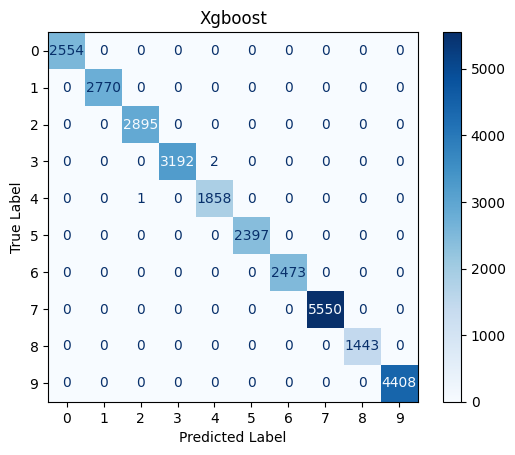

In [31]:
# Visualise and save the XGBoost confusion matrix (matrix `cf` computed above).
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cf)
disp.plot(cmap=plt.cm.Blues)

plt.title("Xgboost")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.savefig("confusion_matrix_xgboost.png", dpi=300, bbox_inches='tight')
plt.show()

# SVC

In [32]:
# 3.2 Support Vector Machine (SVC)
# Default SVC hyperparameters (RBF kernel, C=1.0; no tuning).
# Initialise the Support Vector Machine (SVC) classifier.
model2 = SVC()

In [33]:
# Train Support Vector Machine (SVC) on the (scaled) training set.
model2.fit(X_train,y_train)

SVC()

In [34]:
# Predict class labels for the test set with Support Vector Machine (SVC).
pre_svc = model2.predict(X_test)

In [35]:
# Compute accuracy, macro recall / F1 / precision, MCC and the confusion
# matrix on the test set (same argument order as above: predictions first).
accuracy = accuracy_score(pre_svc,y_test)
recall = recall_score(pre_svc,y_test, average = 'macro')
f1=f1_score(pre_svc,y_test, average='macro')
precision=precision_score(pre_svc,y_test, average='macro')
mcc = matthews_corrcoef(pre_svc,y_test)
cf= confusion_matrix(pre_svc,y_test)

In [36]:
# Report the Support Vector Machine (SVC) configuration and its test-set metrics.
print(model2)
print('accuracy is : ',accuracy,'recall is : ',recall,'f1 is :',f1)
print('precision is',precision)
print('MCC is ',mcc)

SVC()
accuracy is :  0.9874081846799581 recall is :  0.983759130590545 f1 is : 0.9830075350694016
precision is 0.9828285661798846
MCC is  0.9858183251951788


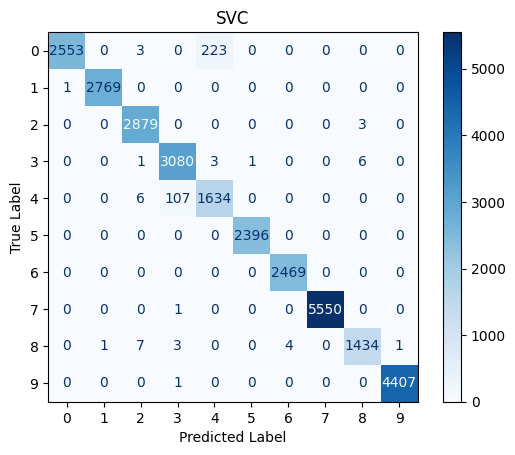

In [37]:
# Visualise and save the Support Vector Machine (SVC) confusion matrix (matrix `cf` computed above).
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cf)
disp.plot(cmap=plt.cm.Blues)

plt.title("SVC")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.savefig("confusion_matrix_svc.png", dpi=300, bbox_inches='tight')
plt.show()

# KNN

In [38]:
# 3.3 k-Nearest Neighbors
# Default k-NN hyperparameters (k=5; no tuning).
# Initialise the k-Nearest Neighbors classifier.
model3= KNeighborsClassifier()

In [39]:
# Train k-Nearest Neighbors on the (scaled) training set.
model3.fit(X_train,y_train)

KNeighborsClassifier()

In [40]:
# Predict class labels for the test set with k-Nearest Neighbors.
pre_knn = model3.predict(X_test)

In [41]:
# Compute accuracy, macro recall / F1 / precision, MCC and the confusion
# matrix on the test set (same argument order as above: predictions first).
accuracy = accuracy_score(pre_knn,y_test)
recall = recall_score(pre_knn,y_test, average = 'macro')
f1=f1_score(pre_knn,y_test, average='macro')
precision=precision_score(pre_knn,y_test, average='macro')
mcc = matthews_corrcoef(pre_knn,y_test)
cf= confusion_matrix(pre_knn,y_test)

In [42]:
# Report the k-Nearest Neighbors configuration and its test-set metrics.
print(model3)
print('accuracy is : ',accuracy,'recall is : ',recall,'f1 is :',f1)
print('precision is',precision)
print('MCC is ',mcc)

KNeighborsClassifier()
accuracy is :  0.9904884405781403 recall is :  0.9888557477009685 f1 is : 0.9872988803355721
precision is 0.9858885122710881
MCC is  0.9892568455406439


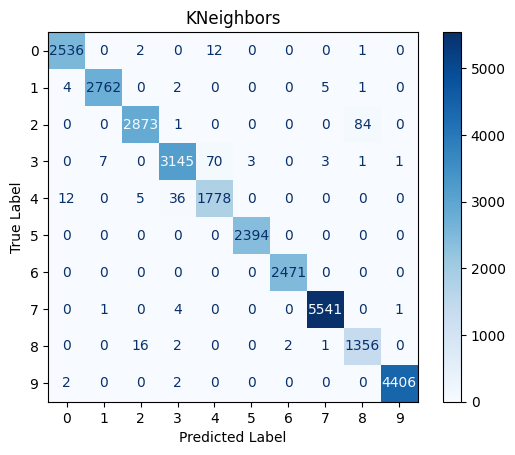

In [43]:
# Visualise and save the k-Nearest Neighbors confusion matrix (matrix `cf` computed above).
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cf)
disp.plot(cmap=plt.cm.Blues)

plt.title("KNeighbors")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.savefig("confusion_matrix_knn.png", dpi=300, bbox_inches='tight')
plt.show()

# Decision Tree

In [44]:
# 3.4 Decision Tree
# Default decision-tree hyperparameters (no tuning, no fixed random_state).
# Initialise the Decision Tree classifier.
model4= DecisionTreeClassifier()

In [45]:
# Train Decision Tree on the (scaled) training set.
model4.fit(X_train,y_train)

DecisionTreeClassifier()

In [46]:
# Predict class labels for the test set with Decision Tree.
pre_dtree = model4.predict(X_test)

In [47]:
# Compute accuracy, macro recall / F1 / precision, MCC and the confusion
# matrix on the test set (same argument order as above: predictions first).
accuracy = accuracy_score(pre_dtree,y_test)
recall = recall_score(pre_dtree,y_test, average = 'macro')
f1=f1_score(pre_dtree,y_test, average='macro')
precision=precision_score(pre_dtree,y_test, average='macro')
mcc = matthews_corrcoef(pre_dtree,y_test)
cf= confusion_matrix(pre_dtree,y_test)

In [48]:
# Report the Decision Tree configuration and its test-set metrics.
print(model4)
print('accuracy is : ',accuracy,'recall is : ',recall,'f1 is :',f1)
print('precision is',precision)
print('MCC is ',mcc)


DecisionTreeClassifier()
accuracy is :  0.999627661374945 recall is :  0.9994666969402581 f1 is : 0.9995297845695019
precision is 0.9995934922381734
MCC is  0.9995792972227807


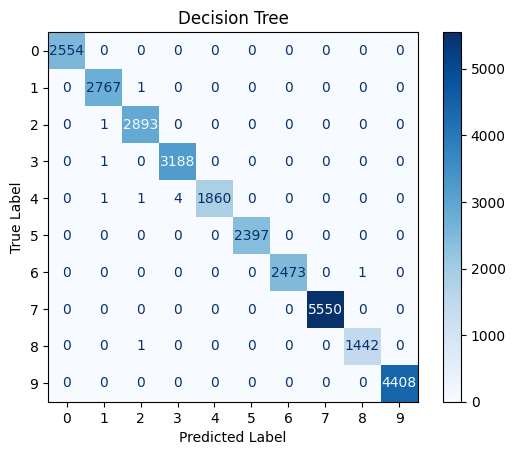

In [49]:
# Visualise and save the Decision Tree confusion matrix (matrix `cf` computed above).
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cf)
disp.plot(cmap=plt.cm.Blues)

plt.title("Decision Tree")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.savefig("confusion_matrix_dtree.png", dpi=300, bbox_inches='tight')
plt.show()

# logistic Regression

In [50]:
# 3.5 Logistic Regression
# Default logistic-regression hyperparameters (no tuning).
# Initialise the Logistic Regression classifier.
model5= LogisticRegression ()

In [51]:
# Train Logistic Regression on the (scaled) training set.
model5.fit(X_train,y_train)

LogisticRegression()

In [52]:
# Predict class labels for the test set with Logistic Regression.
pre_lg = model5.predict(X_test)

In [53]:
# Compute accuracy, macro recall / F1 / precision, MCC and the confusion
# matrix on the test set (same argument order as above: predictions first).
accuracy = accuracy_score(pre_lg,y_test)
recall = recall_score(pre_lg,y_test, average = 'macro')
f1=f1_score(pre_lg,y_test, average='macro')
precision=precision_score(pre_lg,y_test, average='macro')
mcc = matthews_corrcoef(pre_lg,y_test)
cf= confusion_matrix(pre_lg,y_test)

In [54]:
# Report the Logistic Regression configuration and its test-set metrics.
print(model5)
print('accuracy is : ',accuracy,'recall is : ',recall,'f1 is :',f1)
print('precision is',precision)
print('MCC is ',mcc)

LogisticRegression()
accuracy is :  0.992587076464814 recall is :  0.9903278197430158 f1 is : 0.9906428276818797
precision is 0.990971949867045
MCC is  0.9916247280360155


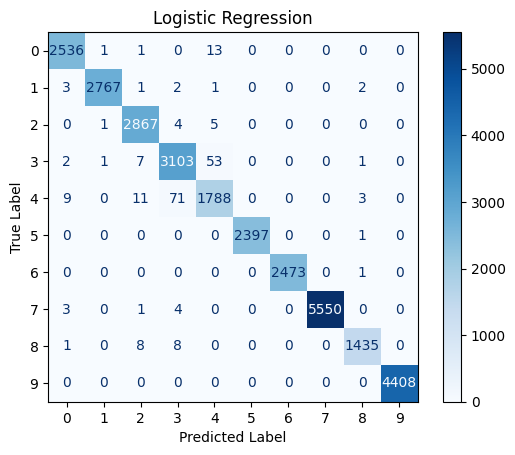

In [55]:
# Visualise and save the Logistic Regression confusion matrix (matrix `cf` computed above).
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cf)
disp.plot(cmap=plt.cm.Blues)

plt.title("Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.savefig("confusion_matrix_lg.png", dpi=300, bbox_inches='tight')
plt.show()

# random Forest

In [56]:
# 3.6 Random Forest
# Default random-forest hyperparameters (no tuning, no fixed random_state).
# Initialise the Random Forest classifier.
model6= RandomForestClassifier()

In [57]:
# Train Random Forest on the (scaled) training set.
model6.fit(X_train,y_train)

RandomForestClassifier()

In [58]:
# Predict class labels for the test set with Random Forest.
pre_rf = model6.predict(X_test)

In [59]:
# Compute accuracy, macro recall / F1 / precision, MCC and the confusion
# matrix on the test set (same argument order as above: predictions first).
accuracy = accuracy_score(pre_rf,y_test)
recall = recall_score(pre_rf,y_test, average = 'macro')
f1=f1_score(pre_rf,y_test, average='macro')
precision=precision_score(pre_rf,y_test, average='macro')
mcc = matthews_corrcoef(pre_rf,y_test)
cf= confusion_matrix(pre_rf,y_test)

In [60]:
# Report the Random Forest configuration and its test-set metrics.
print(model6)
print('accuracy is : ',accuracy,'recall is : ',recall,'f1 is :',f1)
print('precision is',precision)
print('MCC is ',mcc)

RandomForestClassifier()
accuracy is :  0.9999661510340859 recall is :  0.9999462654486834 f1 is : 0.9999574588894522
precision is 0.9999686716791981
MCC is  0.9999617521142814


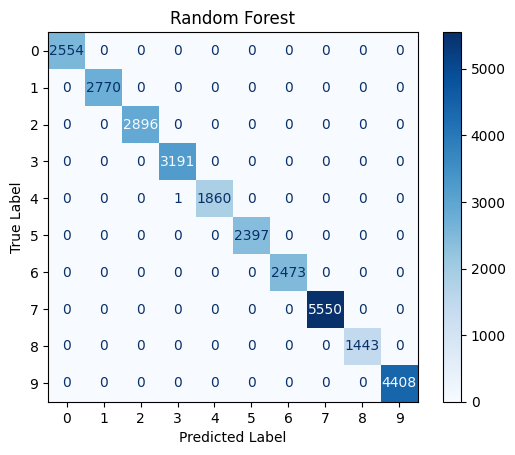

In [61]:
# Visualise and save the Random Forest confusion matrix (matrix `cf` computed above).
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cf)
disp.plot(cmap=plt.cm.Blues)

plt.title("Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.savefig("confusion_matrix_rf.png", dpi=300, bbox_inches='tight')
plt.show()

# Statistical Model 

# lASSO MODEL

In [26]:
# ============================================================
# 3.7-3.9 STATISTICAL MODELS: REGULARISED LOGISTIC REGRESSION
# ============================================================
# 3.7 Lasso (L1) logistic regression
# L1-regularised (Lasso) logistic regression: liblinear solver, C=1.0.
# Initialise the Lasso (L1) logistic regression classifier.
lasso_model = LogisticRegression(penalty='l1', solver='liblinear', C=1.0, random_state=42)

In [27]:
# Train Lasso (L1) logistic regression on the (scaled) training set.
lasso_model.fit(X_train,y_train)

LogisticRegression(penalty='l1', random_state=42, solver='liblinear')

In [28]:
# Predict class labels for the test set with Lasso (L1) logistic regression.
pre_lasso = lasso_model.predict(X_test)

In [29]:
# Compute accuracy, macro recall / F1 / precision, MCC and the confusion
# matrix on the test set (same argument order as above: predictions first).
accuracy = accuracy_score(pre_lasso,y_test)
recall = recall_score(pre_lasso,y_test, average = 'macro')
f1=f1_score(pre_lasso,y_test, average='macro')
precision=precision_score(pre_lasso,y_test, average='macro')
mcc = matthews_corrcoef(pre_lasso,y_test)
cf= confusion_matrix(pre_lasso,y_test)

In [30]:
# Report the Lasso (L1) logistic regression configuration and its test-set metrics.
print(lasso_model)
print('accuracy is : ',accuracy,'recall is : ',recall,'f1 is :',f1)
print('precision is',precision)
print('MCC is ',mcc)

LogisticRegression(penalty='l1', random_state=42, solver='liblinear')
accuracy is :  0.9860203770774802 recall is :  0.9836913951935389 f1 is : 0.9824394757285845
precision is 0.9813835193124009
MCC is  0.9842109670133884


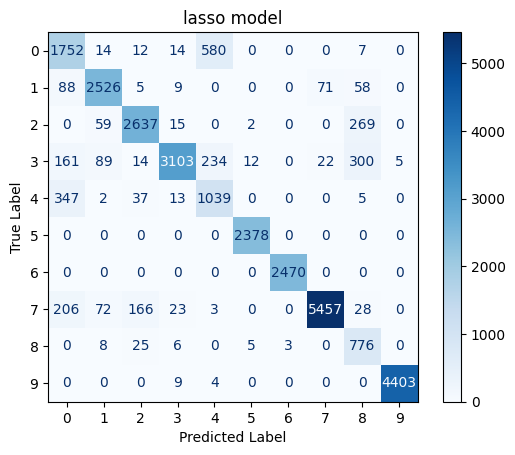

In [48]:
# Visualise and save the Lasso (L1) logistic regression confusion matrix (matrix `cf` computed above).
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cf)
disp.plot(cmap=plt.cm.Blues)

plt.title("lasso model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.savefig("confusion_lasso")

# ridge_model

In [34]:
# 3.8 Ridge (L2) logistic regression
# L2-regularised (Ridge) logistic regression: lbfgs solver, C=1.0.
# Initialise the Ridge (L2) logistic regression classifier.
ridge_model = LogisticRegression(penalty='l2', solver='lbfgs', C=1.0, random_state=42)

In [35]:
# Train Ridge (L2) logistic regression on the (scaled) training set.
ridge_model.fit(X_train,y_train)

LogisticRegression(random_state=42)

In [36]:
# Predict class labels for the test set with Ridge (L2) logistic regression.
pre_ridge = ridge_model.predict(X_test)

In [37]:
# Compute accuracy, macro recall / F1 / precision, MCC and the confusion
# matrix on the test set (same argument order as above: predictions first).
accuracy = accuracy_score(pre_ridge,y_test)
recall = recall_score(pre_ridge,y_test, average = 'macro')
f1=f1_score(pre_ridge,y_test, average='macro')
precision=precision_score(pre_ridge,y_test, average='macro')
mcc = matthews_corrcoef(pre_ridge,y_test)
cf= confusion_matrix(pre_ridge,y_test)

In [38]:
# Report the Ridge (L2) logistic regression configuration and its test-set metrics.
print(ridge_model)
print('accuracy is : ',accuracy,'recall is : ',recall,'f1 is :',f1)
print('precision is',precision)
print('MCC is ',mcc)

LogisticRegression(random_state=42)
accuracy is :  0.992587076464814 recall is :  0.9903278197430158 f1 is : 0.9906428276818797
precision is 0.990971949867045
MCC is  0.9916247280360155


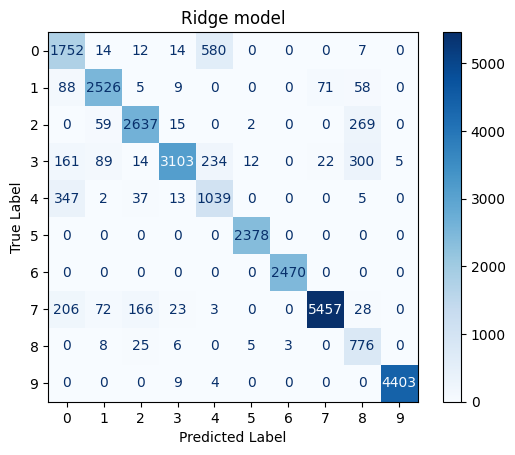

In [49]:
# Visualise and save the Ridge (L2) logistic regression confusion matrix (matrix `cf` computed above).
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cf)
disp.plot(cmap=plt.cm.Blues)

plt.title("Ridge model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.savefig("confusion_Ridge")

# Elastic Regression

In [41]:
# 3.9 Elastic-Net logistic regression
# Elastic-Net logistic regression: saga solver, l1_ratio=0.5, C=1.0.
# Initialise the Elastic-Net logistic regression classifier.
elastic_model = LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5, C=1.0, random_state=42)

In [42]:
# Train Elastic-Net logistic regression on the (scaled) training set.
elastic_model.fit(X_train,y_train)

LogisticRegression(l1_ratio=0.5, penalty='elasticnet', random_state=42,
                   solver='saga')

In [43]:
# Predict class labels for the test set with Elastic-Net logistic regression.
pre_elastic = elastic_model.predict(X_test)

In [44]:
# Compute accuracy, macro recall / F1 / precision, MCC and the confusion
# matrix on the test set (same argument order as above: predictions first).
accuracy = accuracy_score(pre_elastic,y_test)
recall = recall_score(pre_elastic,y_test, average = 'macro')
f1=f1_score(pre_elastic,y_test, average='macro')
precision=precision_score(pre_elastic,y_test, average='macro')
mcc = matthews_corrcoef(pre_elastic,y_test)
cf= confusion_matrix(pre_elastic,y_test)

In [45]:
# Report the Elastic-Net logistic regression configuration and its test-set metrics.
print(elastic_model)
print('accuracy is : ',accuracy,'recall is : ',recall,'f1 is :',f1)
print('precision is',precision)
print('MCC is ',mcc)

LogisticRegression(l1_ratio=0.5, penalty='elasticnet', random_state=42,
                   solver='saga')
accuracy is :  0.8983854043258979 recall is :  0.8900874980540847 f1 is : 0.8647820657798551
precision is 0.8549920176249206
MCC is  0.8855390721261437


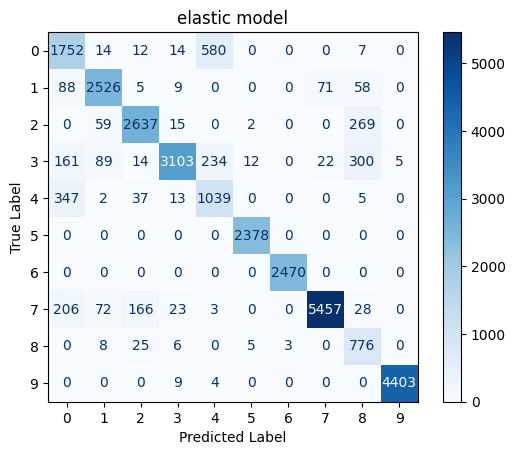

In [50]:
# Visualise and save the Elastic-Net logistic regression confusion matrix (matrix `cf` computed above).
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cf)
disp.plot(cmap=plt.cm.Blues)

plt.title("elastic model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.savefig("confusion_elastic")

## ROC curves and macro AUC

For each model, test labels and predicted labels are one-hot encoded over the 10 classes and one-vs-rest ROC curves / AUC values are computed per class; the macro-averaged AUC is printed and each figure is saved as a PNG.

# ROC

# AUC ROC FOR THE STATISTICAL

lasso_model Macro AUC: 0.990
ridge_model Macro AUC: 0.995
elastic_model Macro AUC: 0.922


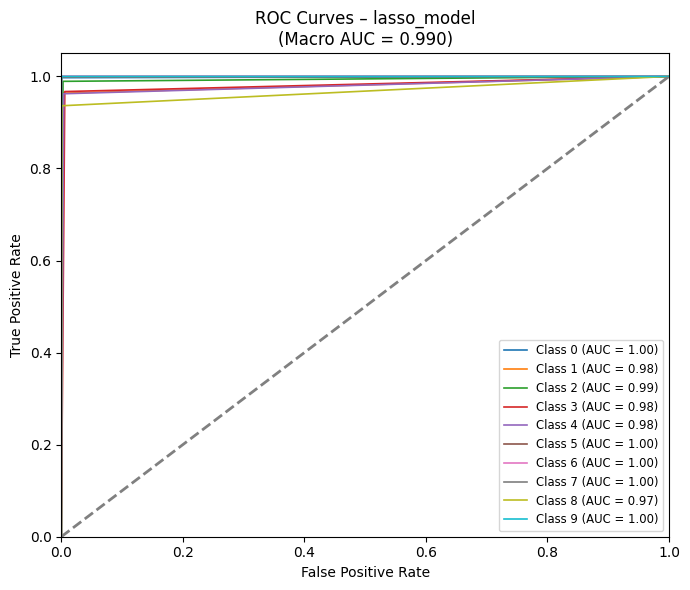

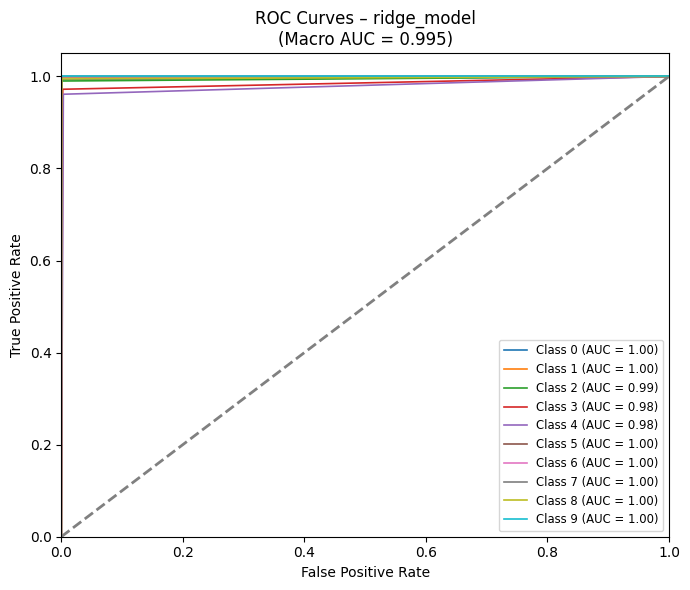

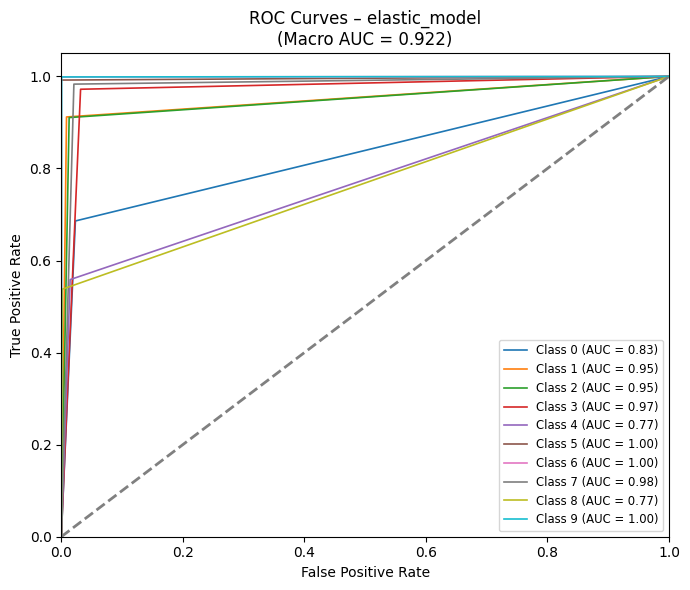

In [47]:
# ============================================================
# ROC CURVES AND MACRO AUC - STATISTICAL (REGULARISED LOGISTIC) MODELS
# ============================================================
# For each model, the test labels and the predicted class labels are
# one-hot encoded (label_binarize, 10 classes) and a one-vs-rest ROC curve
# and AUC are computed per class; the macro-averaged AUC is printed and
# each figure is saved as a PNG file.
# Note: the ROC curves are built from hard class predictions (not from
# predicted probabilities), as in the original study.
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

# Example data structure
results = {
    "lasso_model": pre_lasso,
    "ridge_model": pre_ridge,
    "elastic_model": pre_elastic
}

n_classes = 10
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))

for name, y in results.items():
    # Ensure predictions are probabilities for each class (shape: [n_samples, n_classes])

      # If predictions are class labels, convert to one-hot
    y_bin = label_binarize(y, classes=np.arange(n_classes))


    fpr, tpr, auc_score = {}, {}, {}

    plt.figure(figsize=(7, 6))

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_bin[:, i])
        auc_score[i] = auc(fpr[i], tpr[i])
        plt.plot(fpr[i], tpr[i], lw=1.2, label=f"Class {i} (AUC = {auc_score[i]:.2f})")

    # Macro-average AUC
    auc_macro = roc_auc_score(y_test_bin, y_bin, average="macro")
    print(f"{name} Macro AUC: {auc_macro:.3f}")

    # Diagonal (random guess)
    plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')

    # Customize plot
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curves – {name}\n(Macro AUC = {auc_macro:.3f})')
    plt.legend(loc='lower right', fontsize='small')

    plt.tight_layout()
    plt.savefig(f"ROC_NO_NOISY_AND_NO_HYPERPARAMETER_{name.replace(' ', '_')}.png", dpi=300, bbox_inches='tight')
plt.show()

# Machine learning models

XGBoost Macro AUC: 1.000
Support Vector Machine Macro AUC: 0.991
k-Nearest Neighbors Macro AUC: 0.992
Decision Tree Macro AUC: 1.000
Logistic Regression Macro AUC: 0.995
Random Forest Macro AUC: 1.000


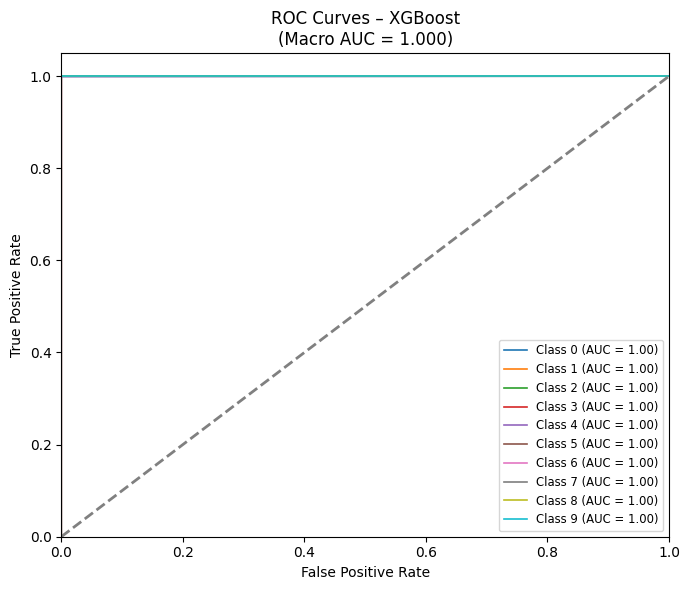

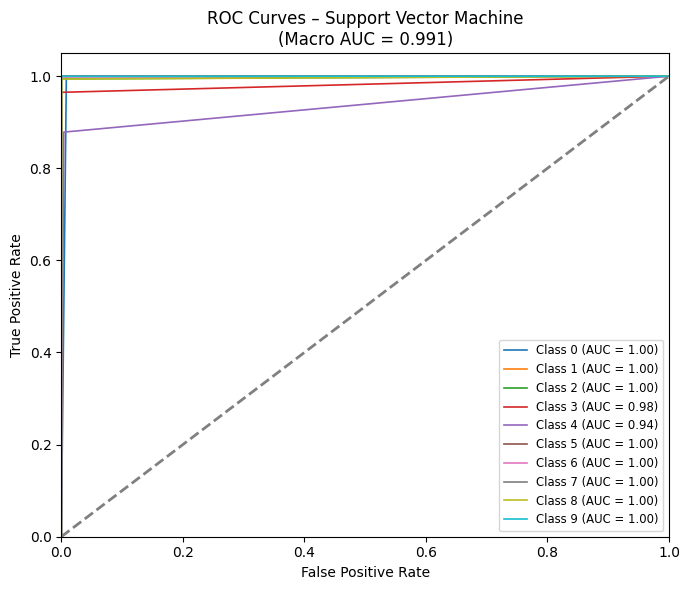

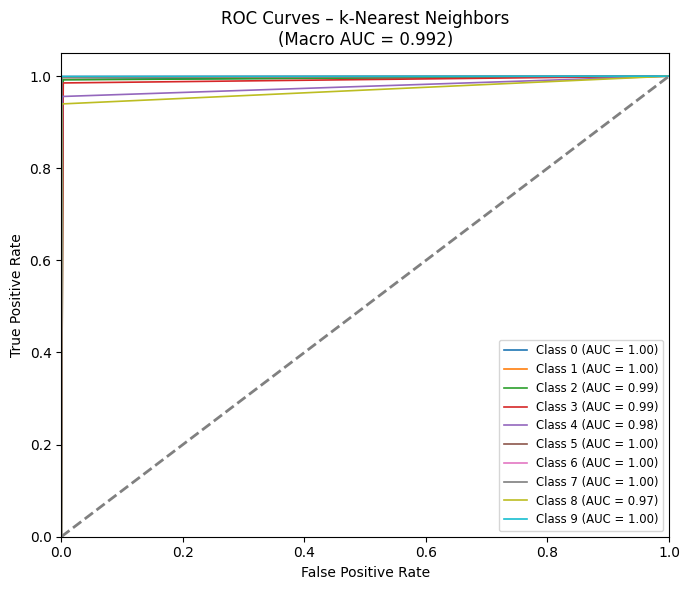

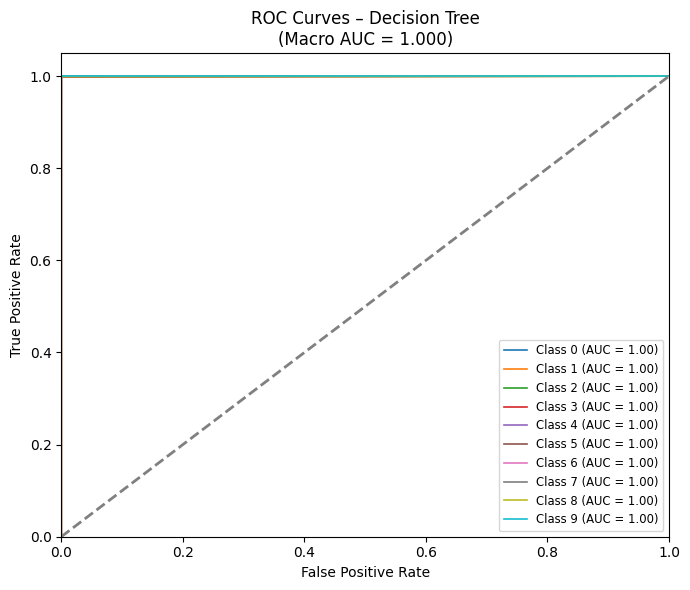

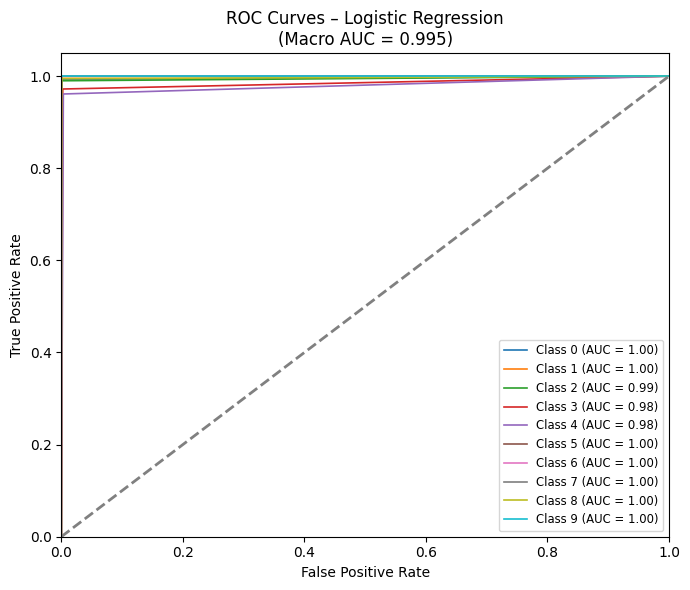

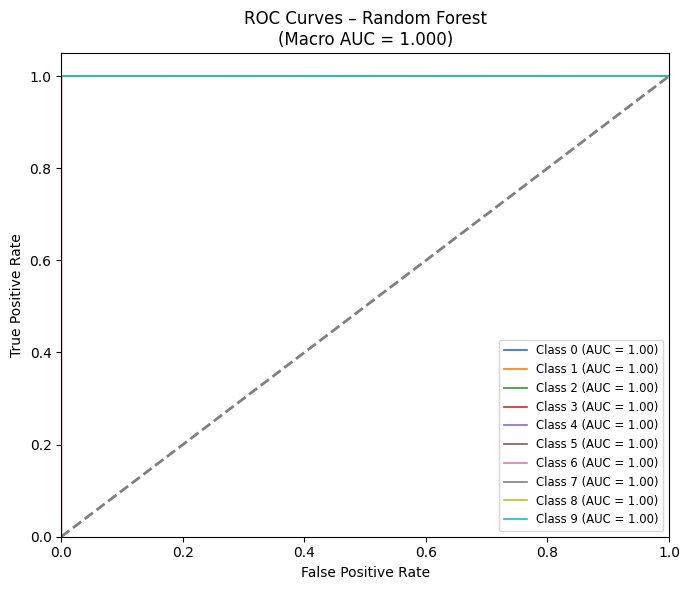

In [62]:
# ============================================================
# ROC CURVES AND MACRO AUC - MACHINE LEARNING MODELS
# ============================================================
# Same one-vs-rest ROC / macro-AUC procedure as above, applied to the six
# machine learning classifiers (hard class predictions, 10 classes).
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

# Example data structure
results = {
    "XGBoost": pre_xgb,
    "Support Vector Machine": pre_svc,
    "k-Nearest Neighbors": pre_knn,
    "Decision Tree": pre_dtree,
    "Logistic Regression": pre_lg,
    "Random Forest": pre_rf
}

n_classes = 10
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))

for name, y in results.items():
    # Ensure predictions are probabilities for each class (shape: [n_samples, n_classes])

      # If predictions are class labels, convert to one-hot
    y_bin = label_binarize(y, classes=np.arange(n_classes))


    fpr, tpr, auc_score = {}, {}, {}

    plt.figure(figsize=(7, 6))
    plt.grid(False)
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_bin[:, i])
        auc_score[i] = auc(fpr[i], tpr[i])
        plt.plot(fpr[i], tpr[i], lw=1.2, label=f"Class {i} (AUC = {auc_score[i]:.2f})")

    # Macro-average AUC
    auc_macro = roc_auc_score(y_test_bin, y_bin, average="macro")
    print(f"{name} Macro AUC: {auc_macro:.3f}")

    # Diagonal (random guess)
    plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')

    # Customize plot
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curves – {name}\n(Macro AUC = {auc_macro:.3f})')
    plt.legend(loc='lower right', fontsize='small')

    plt.tight_layout()
    plt.savefig(f"ROC_NO_NOISY_AND_HYPERPARAMETER_{name.replace(' ', '_')}.png", dpi=300, bbox_inches='tight')
plt.show()